# Laboratório 2 – Visualização de Dados (gabarito) [<img src="https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs_gabs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29/images/colag_logo.svg" style="float: right; margin-right: 0%; vertical-align: middle; width: 6.5%;">](https://colab.research.google.com/github/urielmoreirasilva/ICX532/blob/main/labs_gabs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29.ipynb) [<img src="https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs_gabs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29/images/github_logo.svg" style="float: right; margin-right: 0%; vertical-align: middle; width: 3.25%;">](https://github.com/urielmoreirasilva/ICX532/blob/main/labs_gabs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29.ipynb)

Bem-vindo ao Laboratório 2! Nesta tarefa, aprenderemos mais sobre `array`s, `DataFrame`s, criar visualizações de dados e como escrever funções em Python.

Você deve concluir todo este laboratório e enviá-lo ao Moodle até às 23h59 da data de vencimento.

### Referências
- [BPD: Capítulos 6, 7, 8. 9, 10, 11 e 12](https://notes.dsc10.com/)
- [CIT: Capítulo 6, 7 e 8](https://inferentialthinking.com/)
- Aulas: Tópicos 4, 5, 6 e 7. 

Material adaptado do [DSC10 (UCSD)](https://dsc10.com/) por [Flavio Figueiredo (DCC-UFMG)](https://flaviovdf.io/fcd/) e [Uriel Silva (DEST-UFMG)](https://urielmoreirasilva.github.io)

**<u> NOTA</u>: Não use loops `for` em nenhuma pergunta deste laboratório.** Lembre do Tópico 08 que os loops em Python são lentos, e os loops em `arrays` e `DataFrame`s geralmente devem ser evitados. Como alternativa, devemos idealmente utilizar as funções nativas de bibliotecas como `numpy` e `pandas` para a manipulação desses objetos.

In [1]:
## Imports para esse laboratório
import numpy as np
import pandas as pd

## Opções do MatplotLib 
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Aplicativos da Google Play Store 📲

Neste problema, praticaremos manipulações de DataFrame e visualizações de dados com o [Google Play Store Apps Dataset](https://www.kaggle.com/lava18/google-play-store-apps), extraído da Google Play Store.

Começamos carregando o conjunto de dados de um arquivo `.csv` externo, utilizando o método `pd.csv()`: 

In [2]:
apps = pd.read_csv("https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs_gabs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29/data/googleplaystore.csv")
apps

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000.0,Free,0,Everyone,Art & Design
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,500000.0,Free,0,Everyone,Art & Design;Pretend Play
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000.0,Free,0,Everyone,Art & Design
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000.0,Free,0,Teen,Art & Design
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000.0,Free,0,Everyone,Art & Design;Creativity
...,...,...,...,...,...,...,...,...,...,...
10820,Sya9a Maroc - FR,FAMILY,4.5,38,53M,5000.0,Free,0,Everyone,Education
10821,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100.0,Free,0,Everyone,Education
10822,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,1000.0,Free,0,Everyone,Medical
10823,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,1000.0,Free,0,Mature 17+,Books & Reference


Cada linha no DataFrame `apps` acima corresponde à um aplicativo. Algumas das colunas nas quais estamos interessados aqui são:
- `'Category'`: Categoria à qual o aplicativo pertence;
- `'Rating'`: Avaliação geral do usuário do aplicativo, de 1 a 5 (no momento da recuperação de dados);
- `'Reviews'`: Número de avaliações do aplicativo (no momento da recuperação dos dados);
- `'Installs'`: Número de downloads/instalações do aplicativo (no momento da recuperação dos dados).
- `'Content Rating'`: Público-alvo do aplicativo.

*<u>Nota</u>: Observe que os conteúdos das colunas `'Rating'` e `'Content Rating'` são bem diferentes!*

Note que aqui não definimos o índice do DataFrame! Embora à primeira vista possa parecer que o nome do aplicativo (coluna `App`) seria um bom candidato para índice, os nomes dos aplicativos *não são exclusivos*! 

Podemos verificar a não-exclusividade da coluna `App` através do método `.unique()`. Quando chamado em uma `Series`, este método retorna um `array` contendo todos os valores distintos da Series, sem duplicatas.

In [3]:
len(apps)

10825

In [4]:
len(apps.get('App').unique())

9644

Vemos na célula de código acima que o DataFrame `apps` possui 10.825 linhas, e logo isso significa que existem 10.825 aplicativos no conjunto de dados. Porém, ao utilizar o método `.unique()`, vemos que apenas 9.644 desses nomes de aplicativos são únicos, o que nos leva a concluir que devem existir nomes duplicados.

#### **Pergunta 1.1.** 

É razoável pensar que, em uma escala de 1 a 5, um aplicativo "típico" deve ter uma classificação de aproximadamente 3.
Complete a célula de código abaixo com um histograma da coluna `'Rating'` para verificar esse raciocínio.

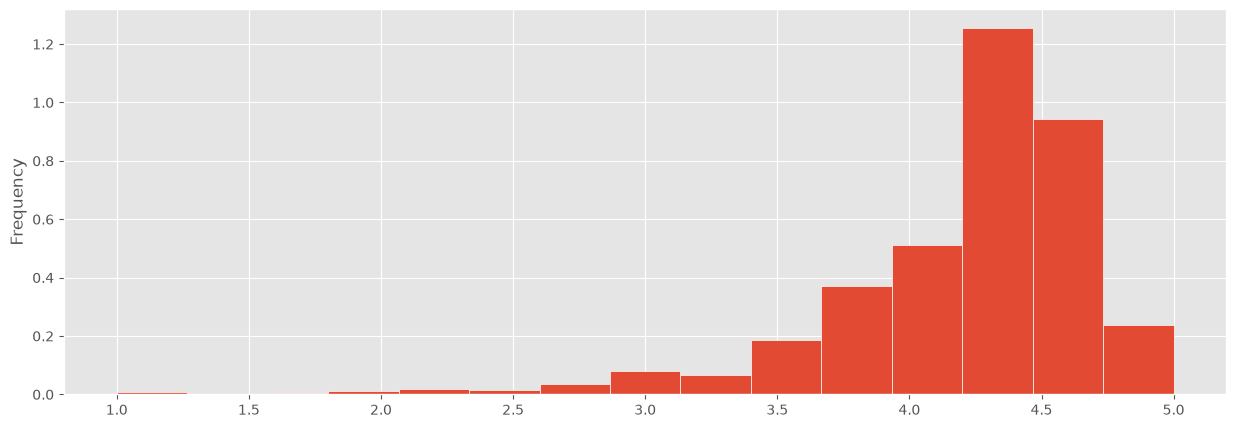

In [5]:
## Descomente e execute!
apps.get("Rating").plot(kind = 'hist',
                        density = True,
                        ec = 'w',
                        bins = 15,
                        figsize = (15, 5));

Agora, uma pergunta natural ao analisar o histograma acima é: "será que os aplicativos com classificações mais altas também têm mais avaliações?"

#### **Pergunta 1.2.** 

Que tipo de gráfico você gostaria de criar para ajudar a determinar se os aplicativos com classificação mais alta também têm mais avaliações? Preencha a célula de texto abaixo com a resposta.

**A.** Gráfico de dispersão

**B.** Gráfico de linha

**C.** Gráfico de barras

**D.** Histograma

> **A**

#### **Pergunta 1.3.** 

Na célula de código abaixo, crie o gráfico correspondente à sua resposta da pergunta acima para ajudá-lo a determinar se os aplicativos com classificação mais alta também são os que têm mais avaliações.

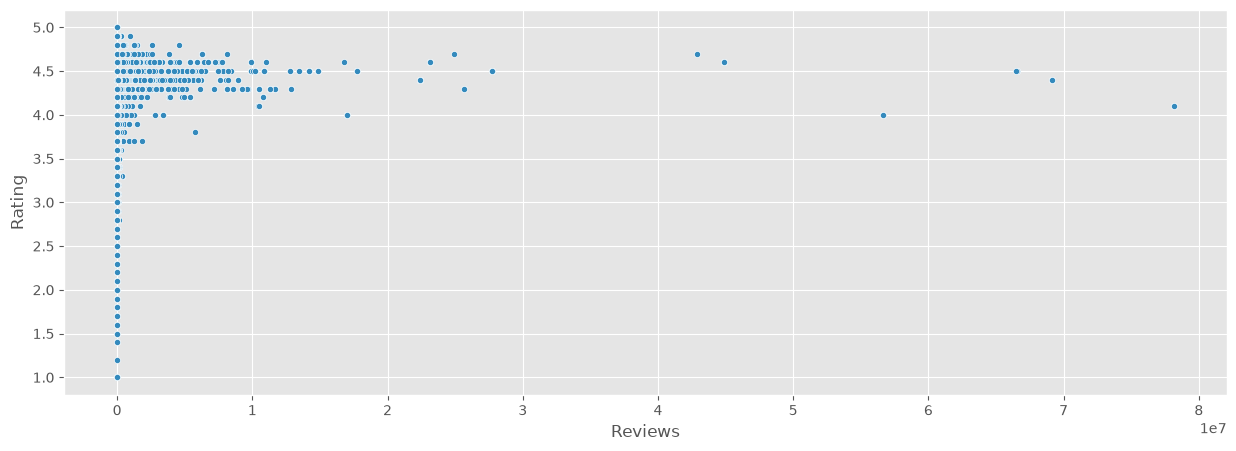

In [6]:
## Descomente e execute!
apps.plot(kind = 'scatter', 
          x = 'Reviews', 
          y = 'Rating',
          ec = 'w',
          figsize = (15, 5));

#### **Pergunta 1.4.**

Na célula de código abaixo, atribua ao objeto `by_content` um DataFrame contendo o número total de aplicativos em `apps`, organizados (ou "estratificados") por `'Content Rating'`.

*<u>Dica 1</u>: Utilize o método `.groupby()` e depois aplique o método `.count()`, agrupando pela coluna desejada.*

*<u>Dica 2</u>: Para sua saída ficar mais "limpa", antes de agrupar chame `.get` em `apps` com uma lista dos nomes de colunas que você deseja manter.*

In [7]:
## Solução sem aplicar a Dica 2 (colunas redundantes)
by_content = apps.groupby('Content Rating').count()
by_content

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Genres
Content Rating,,,,,,,,,
Adults only 18+,3,3,3,3,3,3,3,3,3
Everyone,8702,8702,7420,8702,8702,8702,8702,8702,8702
Everyone 10+,413,413,397,413,413,413,413,413,413
Mature 17+,499,499,461,499,499,499,499,499,499
Teen,1206,1206,1084,1206,1206,1206,1206,1206,1206
Unrated,2,2,1,2,2,2,2,2,2


In [8]:
## Solução escolhendo uma coluna específica (sem redundância)
by_content = apps.get(['App', 'Content Rating']).groupby('Content Rating').count()
by_content

,App
Content Rating,
Adults only 18+,3
Everyone,8702
Everyone 10+,413
Mature 17+,499
Teen,1206
Unrated,2


#### **Pergunta 1.5.**

Execute a célula de código abaixo para verificar o número de linhas contidas em `apps`. Depois,  na célula de código seguinte, confira se o `DataFrame` que você criou na Pergunta 1.4. tem o número correto de elementos aplicando o método `.sum()`.

In [9]:
## Número de linhas em `apps`
apps.shape[0]

10825

In [10]:
## Número de aplicativos em `by_content`
by_content.sum()

App    10825
dtype: int64

#### **Pergunta 1.6.**

Na célula de código abaixo, crie um `DataFrame` e atribua-o ao objeto `install_stats`. Esse DataFrame deve possuir uma única coluna, `'Installs'`, contendo o número médio de `'Installs'` para cada tipo de classificação de conteúdo (`'Content Rating'`).

*<u>Dica 1</u>: Utilize novamente o método `.groupby()`, e depois aplique o método `.mean()`, agrupando pela coluna desejada.*

*<u>Dica 2</u>: Note pelo enunciado que nessa pergunta filtrar as colunas antes de aplicar o `.groupby()` é obrigatório, não opcional.*

*<u>Dica 3</u>: Dependendo de como o seu código for estruturado, pode ser que suas respostas sejam exibidas em notação científica.*

In [11]:
install_stats = apps.get(['Content Rating', 'Installs']).groupby('Content Rating').mean()
install_stats

,Installs
Content Rating,
Adults only 18+,6.666667e+05
Everyone,1.311844e+07
Everyone 10+,3.204330e+07
Mature 17+,1.107112e+07
Teen,2.878636e+07
Unrated,2.525000e+04


#### **Pergunta 1.7.**

Crie na célula de código abaixo um `DataFrame` chamado `top_communication_apps`. Esse DataFrame deve atender às seguintes condições:

1. `'Category'` deve ser igual a `'COMMUNICATION'`;
1. `'Rating'` deve estar entre 4 e 5 (inclusive);
1. O DataFrame deve estar ordenado por `'Rating'`.

*<u>Dica 1</u>: Você pode fazer os filtros/queries/consultas em sequência, ou todos juntos em uma só linha de código utilizando o operador `&` (nesse caso, dentro dos colchetes `[]` é sempre uma boa ideia colocar as condições entre parênteses `()`).*

*<u>Dica 2</u>: A segunda condição pode ser verificada de maneira bem sucinta e "limpa" utilizando o método `.between(a, b)`, que opera elemento-a-elemento em uma `Series` e retorna `True` para cada valor que esteja entre `a` e `b`.*

*<u>Dica 3</u>: Embora você possa simplesmente inspecionar os primeiros e últimos elementos do DataFrame para verificar se a segunda condição foi satisfeita, você também pode analisar a coluna `'Rating'` após chamar `.describe()`. Esse método, quando aplicado a um `DataFrame`, nos fornece um conjunto básico de estatísticas descritivas (incluindo mínimos e máximos) de cada coluna numérica.  

In [12]:
top_communication_apps = apps[(apps.get('Category') == 'COMMUNICATION') & (apps.get('Rating').between(4, 5))]
top_communication_apps = top_communication_apps.sort_values(by = 'Rating')
top_communication_apps

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres
335,Messenger – Text and Video Chat for Free,COMMUNICATION,4.0,56642847,Varies with device,1.000000e+09,Free,0,Everyone,Communication
341,Hangouts,COMMUNICATION,4.0,3419249,Varies with device,1.000000e+09,Free,0,Everyone,Communication
8490,DK Browser,COMMUNICATION,4.0,1,2.4M,1.000000e+01,Free,0,Everyone,Communication
386,Hangouts,COMMUNICATION,4.0,3419433,Varies with device,1.000000e+09,Free,0,Everyone,Communication
384,Hangouts Dialer - Call Phones,COMMUNICATION,4.0,122498,79k,1.000000e+07,Free,0,Everyone,Communication
...,...,...,...,...,...,...,...,...,...,...
6847,BV,COMMUNICATION,5.0,3,1.6M,1.000000e+02,Free,0,Everyone,Communication
7137,Cb browser,COMMUNICATION,5.0,5,3.7M,5.000000e+01,Free,0,Everyone,Communication
9444,EJ messenger,COMMUNICATION,5.0,1,25M,1.000000e+01,Free,0,Teen,Communication
6722,BS-Mobile,COMMUNICATION,5.0,1,683k,5.000000e+01,Free,0,Everyone,Communication


In [13]:
top_communication_apps.describe()

,Rating,Reviews,Installs
count,268.000000,2.680000e+02,2.680000e+02
mean,4.307090,3.040149e+06,1.215079e+08
std,0.203127,9.701682e+06,2.717256e+08
min,4.000000,1.000000e+00,1.000000e+01
25%,4.200000,7.138000e+03,5.000000e+05
50%,4.300000,1.247890e+05,1.000000e+07
75%,4.400000,2.451086e+06,1.000000e+08
max,5.000000,6.911932e+07,1.000000e+09


#### **Pergunta 1.8.**

A partir do `DataFrame` criado na Pergunta 1.7., crie na célula de código abaixo um novo `DataFrame`, que deve ser atribuído ao objeto `top_communication_apps_by_content_rating`. Sua estrutura deve ser a seguinte:

1. O DataFrame deve conter o *número de aplicativos* em `top_communication_apps`, *agrupados* por `'Content_Rating'`;
1. O DataFrame deve conter apenas uma coluna, `'Top_Comm_Apps'`;
1. O DataFrame deve ser ordenado por `'Top_Comm_Apps'`, em ordem decrescente.

*<u>Dica 1</u>: Lembre que ao aplicar `.groupby()` pela coluna de interesse e aplicar o método `.count()`, o `DataFrame` resultante naturalmente será indexado pela coluna de interesse, e os valores de todas as colunas serão iguais.*

*<u>Dica 2</u>: Você pode utilizar o método `.drop()` no `DataFrame` resultante com a opção `columns = List` para remover as colunas em uma lista (`List`) de strings que você não deseja manter.*  

In [14]:
top_communication_apps_by_content_rating = top_communication_apps.groupby('Content Rating').count()
top_communication_apps_by_content_rating = top_communication_apps_by_content_rating.assign(Top_Comm_Apps = top_communication_apps_by_content_rating.get('App'))
top_communication_apps_by_content_rating = top_communication_apps_by_content_rating.sort_values('Top_Comm_Apps', ascending = False)
top_communication_apps_by_content_rating = top_communication_apps_by_content_rating.drop(columns = ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Genres'])
top_communication_apps_by_content_rating

,Top_Comm_Apps
Content Rating,
Everyone,238
Teen,22
Mature 17+,8


#### **Pergunta 1.9.**

Suponha que um aplicativo seja considerado "bom" se esse aplicativo teve pelo menos um milhão de instalações e uma classificação de pelo menos 4. Atribua na célula de código abaixo à variável `best_category` o nome da categoria com o maior número de aplicativos "bons".

*<u>Dica</u>: Além de utilizar todas as ferramentas acima (inclusive múltiplos filtros), pode ser interessante acessar diretamente o índice do `DataFrame` resultante da consulta adequada através do acessador `.index`. Fazer isso nos permite acessar os elementos do índice através de uma indexação `.index[]` usual, e após um `.sort_values` adequado, o primeiro (ou último) valor de `.index` podem ser escolhidos para cumprir a condição acima.*   

In [15]:
best_category = apps[(apps.get('Installs') >= 1e6) & (apps.get('Rating') >= 4)].groupby('Category').count()
best_category.sort_values('App', ascending = False).index[0]

'GAME'

# 2. Renda dos CEOs 💼

No restante deste laboratório, analisaremos um conjunto de dados que trata da remuneração de 2015 dos Diretores Executivos (CEOs) das 100 maiores empresas da Califórnia. 

Os dados foram compilados para uma análise do [Los Angeles Times ](http://spreadsheets.latimes.com/california-ceo-compensation/) e esse consolidado é basicamente o exigido pela Comissão de Valores Mobiliários dos EUA, que faz a regulamentação de todas as empresas de capital aberto. Duas das empresas em nosso conjunto de dados têm dois CEOs, portanto há 102 CEOs no conjunto de dados.

Copiamos os dados da página do LA Times para um arquivo chamado `raw_compensation.csv`. Na página, os autores deixam explícito que todos os valores estão em *milhões de dólares*.

In [16]:
raw_compensation = pd.read_csv("https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs_gabs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29/data/raw_compensation.csv").set_index('Rank')
raw_compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay
Rank,,,,,,,,
1,Mark V. Hurd*,Oracle (Redwood City),$53.25,(No previous year),$0.95,$52.27,$0.02,362.00000
2,Safra A. Catz*,Oracle (Redwood City),$53.24,(No previous year),$0.95,$52.27,$0.02,362.00000
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000
...,...,...,...,...,...,...,...,...
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000
100,Jack Dorsey,Twitter (San Francisco),$0.07,(No previous year),$0.00,$0.00,$0.07,0.63000


Suponha então que você esteja interessado em calcular a média dos salários dos CEOs. 

A princípio isso parece fácil – descomente e tente executar a célula abaixo.

In [17]:
# ## Descomente e execute!
# raw_compensation.get("Total Pay").mean()

Ao executar a célula de código acima, você provavelmente viu um erro. 

Vamos tentar entender por que esse erro ocorreu analisando em mais detalhes os valores na coluna `'Total Pay'`.

#### **Pergunta 2.1.** 

Na célula de código abaixo, utilize a função `type` para definir `total_pay_type` como o tipo do primeiro item da coluna `'Total Pay'`.

In [18]:
total_pay_type = type(raw_compensation.get('Total Pay').iloc[0])
total_pay_type

str

Ao analisar a saída da célula de código acima, entendemos o problema: os valores na coluna `'Total Pay'` são `string`s! 

Não faz sentido calcular a média dos valores de uma string (pois uma string essencialmente armazena texto), então precisamos antes converter esses valores em números.

#### **Pergunta 2.2.** 

Extraia na célula de código abaixo o primeiro valor na coluna `'Total Pay'`. Esse valor corresponde ao salário de 2015 de Mark Hurd, um dos dois CEOs da Oracle em 2015 (lembre que o valor está expresso em *milhões* de dólares). Atribua o valor extraído ao objeto `mark_hurd_pay_string`.

In [19]:
mark_hurd_pay_string = raw_compensation.get('Total Pay').iloc[0]
mark_hurd_pay_string

'$53.25 '

Para convertermos um valor que esteja no formato acima, primeiramente podemos utilizar o método `.strip()` com a opção "`$`" para remover o cifrão:  

In [20]:
"$53.25".strip("$")

'53.25'

Após removermos o cifrão, podemos utilizar a função `float()` para converter a string em um número (mais precisamente um `float`):

In [21]:
float("$53.25".strip("$"))

53.25

Finalmente, como os resultados devem estar em milhões de dólares, multiplicamos o resultado acima por 1 milhão ($10^6$, ou `1e6` em notação científica):

In [22]:
1e6 * float("$53.25".strip("$"))

53250000.0

##### **Pergunta 2.3.**

Utilizando os passos acima, converta na célula de código abaixo a string `mark_hurd_pay_string` em um número expresso *em dólares* (não em milhões) e armazene o resultado na variável `mark_hurd_pay`, cujo tipo deve ser `float`. Atribua o resultado ao objeto `mark_hurd_pay`.

In [23]:
## Aqui utilizamos a notação científica 1e6 = 1.000.000 para evitar erros de digitação :)
mark_hurd_pay = 1e6 * float(mark_hurd_pay_string.strip("$"))
mark_hurd_pay

53250000.0

Suponha agora que você queria calcular o salário médio dos 102 CEOs. Para evitar de copiar e colar o código acima 102 vezes, primeiro vamos criar uma função!

##### **Pergunta 2.4.** 

Defina na célula de código abaixo uma função `convert_pay_string_to_number`, que deve receber como argumento uma `string` (`some_pay_string`) no formato `"$X.XX"` e retornar seu valor em milhões de dólares. Na célula de código seguinte, aplique a sua função à `mark_hurd_pay_string`. O resultado deve ser o mesmo que você obteve anteriormente.

In [24]:
def convert_pay_string_to_number(some_pay_string):
    """Converte uma string como '$100' (em milhões) para um número em dólares."""
    return(1e6 * float(some_pay_string.strip("$")))

In [25]:
## Descomente e execute!
convert_pay_string_to_number(mark_hurd_pay_string)

53250000.0

As funções são sempre úteis quando queremos *generalizar* algum comportamento que queremos para quaisquer argumentos que satisfaçam as nossas condições (além de evitar erros de código ao copiar e colar muitas vezes).

Aqui, por exemplo, podemos agora computar o pagamento de Safra Catzs (o 2º CEO em `raw_compensation`) com uma chamada bem mais simples:

In [26]:
convert_pay_string_to_number(raw_compensation.get('Total Pay').iloc[1])

53240000.0

# 3. Aplicando Funções em DataFrames e Series

Um método é extremamente útil quando queremos aplicar uma função *elemento-a-elemento* em uma `Series` é o método `.apply()`.

Essencialmente, `.apply()` recebe uma função como argumento e aplica essa função a cada elemento da `Series` da qual o método é chamado (ou, de maneira mais geral, a cada linha e coluna de um `DataFrame`).

Continuando com nosso exemplo anterior, vamos aplicar nossa função `convert_pay_string_to_number` à coluna `'Total Pay'` do `DataFrame` `raw_compensation`:

In [28]:
raw_compensation.get('Total Pay').apply(convert_pay_string_to_number)

Rank
1      53250000.0
2      53240000.0
3      44910000.0
4      35980000.0
5      33360000.0
          ...    
98       940000.0
99       810000.0
100       70000.0
101       40000.0
102           0.0
Name: Total Pay, Length: 102, dtype: float64

Abaixo está uma ilustração do que a chamada acima faz:

<img src="https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs_gabs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados%20%28gabarito%29/images/apply.png" width=700/>

É importante notar que, ao chamar `.apply()`, especificamos a função sem `()`, isto é, fornecemos `convert_pay_string_to_number` como argumento, e não `convert_pay_string_to_number()`.

#### **Pergunta 3.1.** 

Na célula de código abaixo, refaça a aplicação acima de `.apply()` com a função `convert_pay_string_to_number` à coluna `'Total Pay'` do `DataFrame` `raw_compensation`. Atribua a `Series` resultante ao objeto `total_pay_dollars`.

In [29]:
total_pay_dollars = raw_compensation.get('Total Pay').apply(convert_pay_string_to_number)
total_pay_dollars

Rank
1      53250000.0
2      53240000.0
3      44910000.0
4      35980000.0
5      33360000.0
          ...    
98       940000.0
99       810000.0
100       70000.0
101       40000.0
102           0.0
Name: Total Pay, Length: 102, dtype: float64

#### **Pergunta 3.2.** 

Utilizando o resultado da Pergunta 3.1., crie um novo `DataFrame` denominado `compensation`, que deve ser uma cópia de `raw_compensation` e conter uma coluna a mais, `'Total_Pay_Dollars'`, cujo conteúdo deve ser o mesmo do objeto `total_pay_dollars` definido acima.

*<u>Dica</u>: Lembre que `.apply()` retorna uma `Series`, e que `.assign()` pode ser utilizado para adicionar uma `Series` a um `DataFrame` como uma nova coluna.*

In [31]:
compensation = raw_compensation.assign(Total_Pay_Dollars = total_pay_dollars)
compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars
Rank,,,,,,,,,
1,Mark V. Hurd*,Oracle (Redwood City),$53.25,(No previous year),$0.95,$52.27,$0.02,362.00000,53250000.0
2,Safra A. Catz*,Oracle (Redwood City),$53.24,(No previous year),$0.95,$52.27,$0.02,362.00000,53240000.0
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000,44910000.0
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000,35980000.0
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000,33360000.0
...,...,...,...,...,...,...,...,...,...
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0
100,Jack Dorsey,Twitter (San Francisco),$0.07,(No previous year),$0.00,$0.00,$0.07,0.63000,70000.0


Finalmente, com todos os salários em números, podemos realizar operações aritméticas com eles!

#### **Pergunta 3.3.**

Na célula de código abaixo, calcule o salário total médio dos CEOs no conjunto de dados.

*<u>Dica</u>: Obtenha primeiro a coluna desejada de `compensation` utilizando `.get()`, e depois utilize o método `.mean()`.* 

In [32]:
average_total_pay = compensation.get('Total_Pay_Dollars').mean()
average_total_pay

np.float64(11445294.11764706)

#### **Pergunta 3.4.** [!]

As empresas pagam os executivos de diversas maneiras: diretamente em dinheiro; concedendo ações ou outro “capital” da empresa; ou com benefícios acessórios (como jatos particulares ✈️). Calcule a proporção do salário de cada CEO que era em dinheiro. (Sua resposta deve ser uma série.)

In [40]:
cash_pay = raw_compensation.get('Cash Pay').apply(convert_pay_string_to_number)
cash_pay

Rank
1        950000.0
2        950000.0
3      24890000.0
4       1000000.0
5       4650000.0
          ...    
98       930000.0
99       710000.0
100           0.0
101       40000.0
102           0.0
Name: Cash Pay, Length: 102, dtype: float64

#### **Pergunta 3.5.** 

As empresas pagam os executivos de diversas maneiras: diretamente em dinheiro; concedendo ações ou outro “capital” da empresa; ou com benefícios acessórios (como jatos particulares ✈️). Calcule a proporção do salário de cada CEO que era em dinheiro. (Sua resposta deve ser uma série.)

In [39]:
compensation = compensation.assign(Cash_Pay_Dollars = cash_pay)
compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars,Cash_Pay_Dollars
Rank,,,,,,,,,,
1,Mark V. Hurd*,Oracle (Redwood City),$53.25,(No previous year),$0.95,$52.27,$0.02,362.00000,53250000.0,950000.0
2,Safra A. Catz*,Oracle (Redwood City),$53.24,(No previous year),$0.95,$52.27,$0.02,362.00000,53240000.0,950000.0
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000,44910000.0,24890000.0
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000,35980000.0,1000000.0
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000,33360000.0,4650000.0
...,...,...,...,...,...,...,...,...,...,...
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0,930000.0
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0,710000.0
100,Jack Dorsey,Twitter (San Francisco),$0.07,(No previous year),$0.00,$0.00,$0.07,0.63000,70000.0,0.0


#### **Pergunta 3.6.** 

As empresas pagam os executivos de diversas maneiras: diretamente em dinheiro; concedendo ações ou outro “capital” da empresa; ou com benefícios acessórios (como jatos particulares ✈️). Calcule a proporção do salário de cada CEO que era em dinheiro. (Sua resposta deve ser uma série.)

In [41]:
cash_proportion = 1e2 * compensation.get('Cash_Pay_Dollars') / compensation.get('Total_Pay_Dollars')
cash_proportion

Rank
1        1.784038
2        1.784373
3       55.421955
4        2.779322
5       13.938849
          ...    
98      98.936170
99      87.654321
100      0.000000
101    100.000000
102           NaN
Length: 102, dtype: float64

Observe atentamente o resultado. A última linha tem um valor estranho, `NaN`. `NaN` significa "não é um número".

Vejamos as últimas linhas do DataFrame:

In [42]:
compensation.take(np.arange(-5, 0))

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars,Cash_Pay_Dollars
Rank,,,,,,,,,,
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0,930000.0
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0,710000.0
100,Jack Dorsey,Twitter (San Francisco),$0.07,(No previous year),$0.00,$0.00,$0.07,0.63000,70000.0,0.0
101,Elon R. Musk,Tesla Motors (Palo Alto),$0.04,6%,$0.04,$0.00,$0.00,0.46000,40000.0,40000.0
102,Lawrence Page***,Alphabet (Mountain View),$0.00,0%,$0.00,$0.00,$0.00,0.00001,0.0,0.0


Notou algo estranho? [emoji ponder] [!]

Por que obtivemos o `NaN`? Atribua 1, 2, 3 ou 4 ao nome `apply_part5` abaixo.
1. A proporção seria 0. Python só pode calcular números diferentes de zero.
2. A `'Proporção entre o salário do CEO e o salário médio do trabalhador da indústria'` é arredondado para 0, o que o Python não sabe como lidar.
3. O cálculo é dividido por 0, portanto o resultado não é um número.

In [ ]:
apply_part5 = ...

Muitos dados reais são confusos. Pode conter zeros, valores vazios ou `NaN`'s (não-um-número) que precisamos observar ao realizar cálculos!

Tudo bem, de volta aos nossos CEOs. Confira a coluna `'% Change'` em `compensation`. Mostra o aumento percentual na remuneração do CEO em relação ao ano anterior. Para CEOs sem nenhum ano anterior registrado, em vez disso diz `'(No previous year)'`. Os valores nesta coluna são *strings*, não números, portanto, assim como a coluna `'Total Pay'`, ela não pode ser usada sem um pouco de trabalho extra.

Dado o seu salário atual e o aumento percentual em relação ao ano anterior, você pode calcular o salário do ano anterior. O salário deste ano e o salário do ano passado estão relacionados pela fórmula:

$$\text{salário deste ano} = \text{salário do ano passado} \cdot \left(1+\dfrac{\text{aumento percentual}}{100}\right)$$

Por exemplo, se você ganhou \$600 no ano passado e seu salário aumentou 50\%, então

$$\begin{align}
\text{pagamento deste ano} &= \text{600} \cdot \left(1+\dfrac{\text{50}}{100}\right)\\
&= \text{600} \cdot (1.5) \\
&= 900
\end{align}$$

Como sabemos como o salário deste ano e o salário do ano passado estão matematicamente relacionados, podemos resolver esta equação para o salário do ano passado para fornecer uma fórmula para o salário do ano anterior se conhecermos o salário do ano atual e o aumento percentual do ano anterior para o ano atual. Fazendo um pouco de álgebra, encontramos:

$$\text{salário do ano passado} = \dfrac{\text{salário deste ano}}{\left(1+\dfrac{\text{aumento percentual}}{100}\right)}$$

#### **Pergunta 3.6.** 

Crie um novo DataFrame chamado `with_previous_compensation`. Deve ser uma cópia de `compensation`, mas com os CEOs `'(No previous year)'` filtrados, e com uma coluna extra chamada `'Previous_Total_Pay'`. Essa coluna deve conter o salário de cada CEO em 2014.

*Dica 1:* Esta pergunta envolve vários passos, mas cada um envolve algo que você já aprendeu a fazer. Dê um passo de cada vez, usando quantas linhas forem necessárias. Você pode imprimir seus resultados após cada etapa para ter certeza de que está no caminho certo.

*Dica 2:* Você precisará definir uma função para converter strings de porcentagem, como `'-15%'`, em números. Você pode fazer isso logo acima do outro código.

*Dica 3:* Se você vir um erro dizendo `unsupported operand type(s) for +: 'int' and 'Series'`, tente mudar a ordem de sua operação. Em vez de escrever algo como `1 + series`, escreva `series + 1`.

In [ ]:
# Você pode escrever códigos de passos intermediários aqui!
with_previous_compensation = ...
with_previous_compensation

#### **Pergunta 3.7.** 

Qual foi o salário médio desses CEOs em 2014?

In [ ]:
average_pay_2014 = ...
average_pay_2014

# 4. Distribuição de Riqueza 💰 [!]

Anteriormente, calculamos a remuneração média entre os CEOs em nosso conjunto de dados de 102 CEOs. No entanto, a média não nos diz tudo sobre os montantes pagos aos CEO. Talvez apenas alguns CEOs ganhem a maior parte do dinheiro, mesmo entre estes 102.

Podemos usar um *histograma de densidade* para exibir mais informações sobre um conjunto de números. [Aqui está um exemplo](https://dsc10.com/resources/lectures/lec07/lec07.html#Plotting-a-density-histogram) do código que usamos para criar histogramas.

#### **Pergunta 4.1.**

Faça um histograma de densidade da remuneração dos CEOs em `compensation`.

<Axes: ylabel='Frequency'>

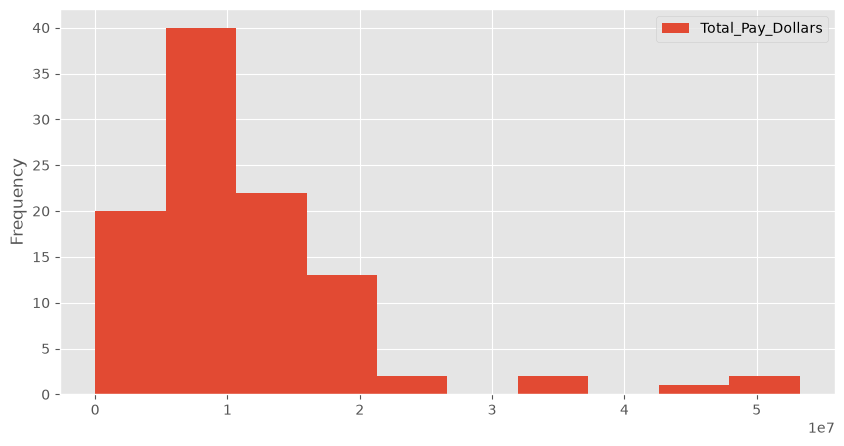

In [54]:
compensation.plot(kind = 'hist',
                 y = 'Total_Pay_Dollars')

#### **Pergunta 4.2.** 

Olhando para o histograma, quantos CEOs ganharam mais de \$30 milhões? Faça um bom palpite. (Responda à pergunta preenchendo sua resposta manualmente. Você terá que fazer um pouco de aritmética; sinta-se à vontade para usar Python como calculadora.)

In [49]:
num_ceos_more_than_30_million = compensation[compensation.get('Total_Pay_Dollars') > 1e6 * 30]
num_ceos_more_than_30_million

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars,Cash_Pay_Dollars
Rank,,,,,,,,,,
1,Mark V. Hurd*,Oracle (Redwood City),$53.25,(No previous year),$0.95,$52.27,$0.02,362.0,53250000.0,950000.0
2,Safra A. Catz*,Oracle (Redwood City),$53.24,(No previous year),$0.95,$52.27,$0.02,362.0,53240000.0,950000.0
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.0,44910000.0,24890000.0
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.0,35980000.0,1000000.0
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.0,33360000.0,4650000.0


# Linha de chegada 🏁

Parabéns! Você concluiu o Laboratório 2 com sucesso 👏👏👏

Para enviar sua tarefa:

1. Selecione `Kernel -> Restart Kernel and Run All Cells` para garantir que você executou todas as células, incluindo as células de teste.
1. Leia o notebook do começo ao fim com cuidado para ter certeza de que está tudo bem e que todos os testes foram aprovados.
1. Baixe seu notebook usando `File -> Save and Export Notebook As -> HTML` e, em seguida, carregue seu notebook para o Moodle.